#  Genetic Programming: ewolucja programu w drzewach AST

Spektakularny pokaz programowania genetycznego: **nie podajemy wzoru**, tylko przykłady wejście → wyjście.

Ukryty cel demonstracji:

\[
y = x^3 - 2x^2 + 3x + 5
\]

Algorytm nie zna tego wzoru. Ma go **wyhodować** z losowych drzew programu.

Proces:

**populacja → fitness → selekcja → krzyżowanie → mutacja → nowe pokolenie**

**Część II — autoprogramowanie** (sekcje 9–13): wyhodowany program sam się upraszcza, a następnie
algorytm **pisze kod źródłowy metaklasy Pythona**, kompiluje go i uruchamia. Metaklasa — po odpowiedzi
użytkownika **TAK!** na pytanie *„Czy utworzyć funkcję?”* — buduje z drzewa AST nową funkcję o nazwie
`m_wielomian`, którą następnie wywołujemy na wybranych wartościach.

**drzewo GP → wielomian kanoniczny → kod metaklasy → metaklasa → pytanie → `m_wielomian` → użycie**

In [1]:
import random
import math
import ast
import copy
from dataclasses import dataclass

SEED = 10
random.seed(SEED)

# Dane uczące. Wzór poniżej służy WYŁĄCZNIE do przygotowania przykładów.
X = list(range(-5, 6))
Y = [x**3 - 2*x*x + 3*x + 5 for x in X]

print("Algorytm dostaje tylko te pary:")
list(zip(X, Y))

Algorytm dostaje tylko te pary:


[(-5, -185),
 (-4, -103),
 (-3, -49),
 (-2, -17),
 (-1, -1),
 (0, 5),
 (1, 7),
 (2, 11),
 (3, 23),
 (4, 49),
 (5, 95)]

## 1. Reprezentacja osobnika

Każdy osobnik jest drzewem wyrażenia matematycznego.

Przykład:

```text
        +
       / \
      *   3
     / \
    x   x
```

reprezentuje:

```python
x*x + 3
```

In [2]:
OPS = ["+", "-", "*"]
CONSTANTS = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

@dataclass
class Node:
    kind: str
    value: object
    left: object = None
    right: object = None

def clone(node):
    return copy.deepcopy(node)

def terminal():
    if random.random() < 0.55:
        return Node("var", "x")
    return Node("const", random.choice(CONSTANTS))

def random_tree(max_depth=4, grow=True):
    if max_depth == 0 or (grow and random.random() < 0.30):
        return terminal()
    return Node(
        "op",
        random.choice(OPS),
        random_tree(max_depth - 1, grow),
        random_tree(max_depth - 1, grow),
    )

def evaluate(node, x):
    if node.kind == "var":
        return x
    if node.kind == "const":
        return node.value

    a = evaluate(node.left, x)
    b = evaluate(node.right, x)

    if node.value == "+":
        return a + b
    if node.value == "-":
        return a - b
    if node.value == "*":
        return a * b

    raise ValueError("Nieznany operator")

def to_expr(node):
    if node.kind == "var":
        return "x"
    if node.kind == "const":
        return str(node.value)
    return f"({to_expr(node.left)} {node.value} {to_expr(node.right)})"

def tree_size(node):
    if node.kind != "op":
        return 1
    return 1 + tree_size(node.left) + tree_size(node.right)

# szybki test reprezentacji
sample = Node("op", "+",
              Node("op", "*", Node("var", "x"), Node("var", "x")),
              Node("op", "*", Node("const", 3), Node("var", "x")))

print(to_expr(sample))
print([evaluate(sample, x) for x in [1, 2, 3, 4]])

((x * x) + (3 * x))
[4, 10, 18, 28]


## 2. Fitness

Minimalizujemy błąd:

\[
MAE = \frac{1}{n}\sum_i |f(x_i)-y_i|
\]

Dodajemy bardzo małą karę za rozmiar drzewa, aby ewolucja nie produkowała bez końca gigantycznych wyrażeń.

In [3]:
def error(node):
    try:
        values = [evaluate(node, x) for x in X]
        if any(abs(v) > 10**12 for v in values):
            return 10**12
        mae = sum(abs(v - y) for v, y in zip(values, Y)) / len(X)
        complexity_penalty = 0.0002 * tree_size(node)
        return mae + complexity_penalty
    except Exception:
        return 10**12

# tylko kontrola mechanizmu fitness na przykładowym drzewie
print("Przykładowy błąd:", error(sample))

Przykładowy błąd: 41.54685454545454


## 3. Krzyżowanie i mutacja

Krzyżowanie nie miesza liczb w tablicy. **Wymienia całe poddrzewa programu.**

Mutacja może zastąpić wybrany fragment nowym losowym fragmentem.

In [4]:
def paths(node, prefix=()):
    result = [prefix]
    if node.kind == "op":
        result += paths(node.left, prefix + ("L",))
        result += paths(node.right, prefix + ("R",))
    return result

def get_subtree(node, path):
    current = node
    for step in path:
        current = current.left if step == "L" else current.right
    return current

def set_subtree(node, path, replacement):
    if not path:
        return clone(replacement)

    root = clone(node)
    current = root
    for step in path[:-1]:
        current = current.left if step == "L" else current.right

    if path[-1] == "L":
        current.left = clone(replacement)
    else:
        current.right = clone(replacement)
    return root

def crossover(a, b):
    pa = random.choice(paths(a))
    pb = random.choice(paths(b))
    child = set_subtree(a, pa, get_subtree(b, pb))
    return child

def mutate(node, max_new_depth=2):
    p = random.choice(paths(node))
    replacement = random_tree(max_new_depth, grow=True)
    return set_subtree(node, p, replacement)

# test techniczny
a = random_tree(3)
b = random_tree(3)
child = crossover(a, b)
mutant = mutate(child)

print("A:     ", to_expr(a))
print("B:     ", to_expr(b))
print("Child: ", to_expr(child))
print("Mutant:", to_expr(mutant))

A:      ((-1 + (x + x)) - 0)
B:      4
Child:  ((4 + (x + x)) - 0)
Mutant: ((4 + 2) - 0)


## 4. Selekcja turniejowa

Kilku osobników wchodzi do mini-turnieju. Wygrywa ten z najmniejszym błędem.

In [5]:
def tournament(population, k=5):
    contestants = random.sample(population, k)
    return min(contestants, key=error)

## 5. Ewolucja

Parametry są dobrane tak, aby demonstracja była szybka, ale nadal pokazywała prawdziwy proces ewolucyjny.

In [6]:
def evolve(
    population_size=1000,
    generations=120,
    elite_size=25,
    mutation_rate=0.35,
    crossover_rate=0.95,
    max_initial_depth=3,
    verbose=True,
):
    population = [random_tree(max_initial_depth, grow=True) for _ in range(population_size)]
    history = []

    for generation in range(generations + 1):
        population.sort(key=error)
        best = population[0]
        best_error = error(best)
        history.append(best_error)

        if verbose:
            print(
                f"Gen {generation:3d} | error={best_error:10.6f} | "
                f"size={tree_size(best):3d} | {to_expr(best)}"
            )

        # kara za złożoność zostaje, ale MAE jest wtedy dokładnie 0
        predictions = [evaluate(best, x) for x in X]
        exact = predictions == Y
        if exact:
            return best, history

        new_population = [clone(ind) for ind in population[:elite_size]]

        while len(new_population) < population_size:
            parent1 = tournament(population, k=7)

            if random.random() < crossover_rate:
                parent2 = tournament(population, k=7)
                child = crossover(parent1, parent2)
            else:
                child = clone(parent1)

            if random.random() < mutation_rate:
                child = mutate(child)

            # przeciwdziałanie "bloat", czyli niekontrolowanemu puchnięciu drzew
            if tree_size(child) > 80:
                child = random_tree(3, grow=True)

            new_population.append(child)

        population = new_population

    population.sort(key=error)
    return population[0], history

best, history = evolve()

print("\n NAJLEPSZY WYHODOWANY PROGRAM:")
print(to_expr(best))
print("Fitness/error:", error(best))

Gen   0 | error=  6.638164 | size=  9 | (((x + -1) * x) * (-1 + x))


Gen   1 | error=  5.457545 | size= 15 | (((2 + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   2 | error=  5.457545 | size= 15 | (((2 + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   3 | error=  3.096709 | size= 29 | ((((x + (((x * 0) * (x - 0)) * ((x + -1) * x))) + 3) + (((x * x) - (x + x)) * x)) + x)


Gen   4 | error=  0.004200 | size= 21 | (((2 + 3) + (((x * x) - (x + (x + (x - (2 + x))))) * x)) + x)

 NAJLEPSZY WYHODOWANY PROGRAM:
(((2 + 3) + (((x * x) - (x + (x + (x - (2 + x))))) * x)) + x)
Fitness/error: 0.004200000000000001


## 6. Weryfikacja odkrytego programu

Sprawdzamy wartości na danych uczących i na nowych punktach.

In [7]:
def target(x):
    return x**3 - 2*x*x + 3*x + 5

print("x | target | evolved")
print("-" * 31)

for x in range(-8, 9):
    pred = evaluate(best, x)
    print(f"{x:2d} | {target(x):7d} | {pred:7}")

assert all(evaluate(best, x) == target(x) for x in X), \
    "Najlepszy osobnik nie odtworzył danych treningowych dokładnie."

# Test poza zakresem danych użytych przez ewolucję
TEST_X = [-12, -9, 7, 11, 15]
generalizes = all(evaluate(best, x) == target(x) for x in TEST_X)

print("\nGeneralizacja poza zakresem treningowym:", generalizes)

if generalizes:
    print("Ewolucja odkryła funkcję równoważną ukrytemu wzorowi, a nie tylko tabelę odpowiedzi.")

x | target | evolved
-------------------------------
-8 |    -659 |    -659
-7 |    -457 |    -457
-6 |    -301 |    -301
-5 |    -185 |    -185
-4 |    -103 |    -103
-3 |     -49 |     -49
-2 |     -17 |     -17
-1 |      -1 |      -1
 0 |       5 |       5
 1 |       7 |       7
 2 |      11 |      11
 3 |      23 |      23
 4 |      49 |      49
 5 |      95 |      95
 6 |     167 |     167
 7 |     271 |     271
 8 |     413 |     413

Generalizacja poza zakresem treningowym: True
Ewolucja odkryła funkcję równoważną ukrytemu wzorowi, a nie tylko tabelę odpowiedzi.


## 7. Czy to naprawdę Python AST?

Tak. Odkryte wyrażenie zamieniamy na **prawdziwe drzewo składniowe Pythona**, kompilujemy i uruchamiamy.

In [8]:
expr_source = to_expr(best)
parsed = ast.parse(expr_source, mode="eval")

print(ast.dump(parsed, indent=2))

compiled = compile(parsed, "<evolved-program>", "eval")

def evolved_ast_function(x):
    return eval(compiled, {"__builtins__": {}}, {"x": x})

print("\nTest skompilowanego AST:")
for x in [2, 5, 9]:
    print(x, evolved_ast_function(x), target(x))
    assert evolved_ast_function(x) == target(x)

Expression(
  body=BinOp(
    left=BinOp(
      left=BinOp(
        left=Constant(value=2),
        op=Add(),
        right=Constant(value=3)),
      op=Add(),
      right=BinOp(
        left=BinOp(
          left=BinOp(
            left=Name(id='x', ctx=Load()),
            op=Mult(),
            right=Name(id='x', ctx=Load())),
          op=Sub(),
          right=BinOp(
            left=Name(id='x', ctx=Load()),
            op=Add(),
            right=BinOp(
              left=Name(id='x', ctx=Load()),
              op=Add(),
              right=BinOp(
                left=Name(id='x', ctx=Load()),
                op=Sub(),
                right=BinOp(
                  left=Constant(value=2),
                  op=Add(),
                  right=Name(id='x', ctx=Load())))))),
        op=Mult(),
        right=Name(id='x', ctx=Load()))),
    op=Add(),
    right=Name(id='x', ctx=Load())))

Test skompilowanego AST:
2 11 11
5 95 95
9 599 599


## 8. Wykres ewolucji

Na wykresie widać, jak kolejne pokolenia obniżają błąd.

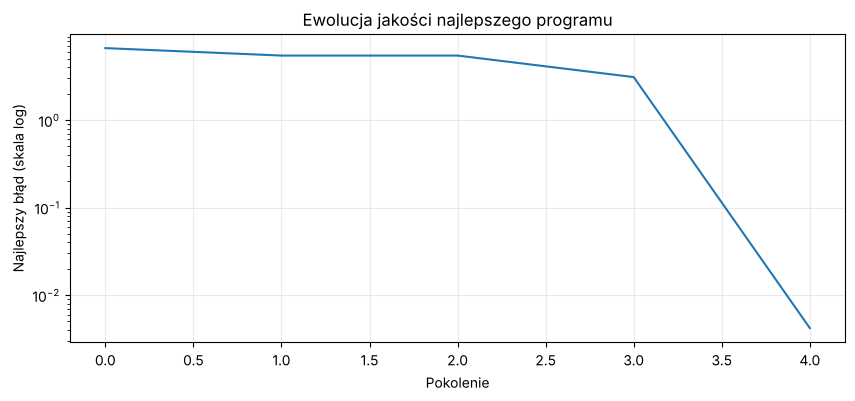

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history)
plt.yscale("log")
plt.xlabel("Pokolenie")
plt.ylabel("Najlepszy błąd (skala log)")
plt.title("Ewolucja jakości najlepszego programu")
plt.grid(True, alpha=0.25)
plt.show()

# Część II — Autoprogramowanie

Do tej pory ewolucja wyhodowała **drzewo wyrażenia**. Teraz program zrobi coś więcej:
**napisze kolejny program**, który z kolei utworzy funkcję.

| Poziom | Kto tworzy | Co powstaje |
|---|---|---|
| 0 | człowiek | operatory GP (sekcje 1–5) |
| 1 | ewolucja | drzewo `best` |
| 2 | algorytm upraszczający | współczynniki wielomianu |
| 3 | **generator kodu** | *tekst źródłowy* metaklasy `MetaWielomian` |
| 4 | `compile` + `exec` | obiekt metaklasy |
| 5 | **metaklasa** (po odpowiedzi TAK!) | AST i obiekt funkcji `m_wielomian` |

## 9. Algorytm czyta własny program: redukcja drzewa do wielomianu

Drzewo używa tylko `+`, `-`, `*`, więc **zawsze** jest wielomianem od `x`.
Zamiast ufać wyglądowi wyrażenia, rozwijamy je symbolicznie: każdy węzeł zamieniamy na słownik
`{stopień: współczynnik}` i wykonujemy na nich arytmetykę wielomianów.

In [10]:
def to_poly(node):
    """Rozwija drzewo GP do postaci {stopień: współczynnik} (dokładna arytmetyka całkowitoliczbowa)."""
    if node.kind == "var":
        return {1: 1}
    if node.kind == "const":
        return {0: node.value}

    a, b = to_poly(node.left), to_poly(node.right)
    out = {}
    if node.value in ("+", "-"):
        sign = 1 if node.value == "+" else -1
        for d, c in a.items():
            out[d] = out.get(d, 0) + c
        for d, c in b.items():
            out[d] = out.get(d, 0) + sign * c
    elif node.value == "*":
        for da, ca in a.items():
            for db, cb in b.items():
                out[da + db] = out.get(da + db, 0) + ca * cb
    else:
        raise ValueError(f"Nieznany operator: {node.value}")
    return {d: c for d, c in out.items() if c != 0}

def poly_coefficients(poly):
    """Krotka współczynników rosnąco: (a0, a1, ..., an)."""
    degree = max(poly) if poly else 0
    return tuple(poly.get(d, 0) for d in range(degree + 1))

def poly_to_str(coeffs):
    parts = []
    for d in range(len(coeffs) - 1, -1, -1):
        c = coeffs[d]
        if c == 0:
            continue
        sign = "-" if c < 0 else "+"
        mag = abs(c)
        if d == 0:
            term = f"{mag}"
        elif d == 1:
            term = "x" if mag == 1 else f"{mag}*x"
        else:
            term = f"x**{d}" if mag == 1 else f"{mag}*x**{d}"
        parts.append((sign, term))
    if not parts:
        return "0"
    first_sign, first_term = parts[0]
    text = ("-" if first_sign == "-" else "") + first_term
    for sign, term in parts[1:]:
        text += f" {sign} {term}"
    return text

WSPOLCZYNNIKI = poly_coefficients(to_poly(best))

print("Wyhodowane drzewo  :", to_expr(best))
print("Rozmiar drzewa     :", tree_size(best), "węzłów")
print("Współczynniki a0..an:", WSPOLCZYNNIKI)
print("Postać kanoniczna  :", poly_to_str(WSPOLCZYNNIKI))

# kontrola: redukcja nie może zmienić znaczenia programu
assert all(
    sum(c * x**d for d, c in enumerate(WSPOLCZYNNIKI)) == evaluate(best, x)
    for x in range(-50, 51)
), "Redukcja do wielomianu zmieniła wartości programu!"
print("\nRedukcja zachowuje wartości programu na x ∈ [-50, 50]: True")

Wyhodowane drzewo  : (((2 + 3) + (((x * x) - (x + (x + (x - (2 + x))))) * x)) + x)
Rozmiar drzewa     : 21 węzłów
Współczynniki a0..an: (5, 3, -2, 1)
Postać kanoniczna  : x**3 - 2*x**2 + 3*x + 5

Redukcja zachowuje wartości programu na x ∈ [-50, 50]: True


## 10. Algorytm pisze kod metaklasy

Generator kodu nie korzysta z gotowej klasy z notebooka. **Składa tekst źródłowy** metaklasy,
wstawiając w niego współczynniki odkryte przez ewolucję i docelową nazwę funkcji.
Ten tekst jest potem:

1. parsowany do AST (`ast.parse`) — dowód, że to poprawny Python,
2. kompilowany (`compile`),
3. wykonywany (`exec`) w izolowanej przestrzeni nazw — dopiero wtedy metaklasa zaczyna istnieć.

Co robi wygenerowana metaklasa w chwili tworzenia klasy:

- zadaje pytanie **„Czy utworzyć funkcję m_wielomian?”**,
- przy odpowiedzi **TAK!** buduje *węzeł po węźle* drzewo `ast.FunctionDef` (schemat Hornera),
  kompiluje je i dołącza gotową funkcję do klasy,
- przy innej odpowiedzi tworzy klasę **bez** funkcji.

In [11]:
import textwrap

NAZWA_FUNKCJI = "m_wielomian"

def wygeneruj_zrodlo_metaklasy(wspolczynniki, nazwa_funkcji, nazwa_metaklasy="MetaWielomian"):
    """Autoprogramowanie: zwraca TEKST kodu źródłowego metaklasy."""
    opis = poly_to_str(wspolczynniki)
    return textwrap.dedent(f"""
        import ast
        import linecache

        class {nazwa_metaklasy}(type):
            \"\"\"Metaklasa wygenerowana automatycznie z wyniku programowania genetycznego.

            Na żądanie (odpowiedź TAK!) tworzy funkcję {nazwa_funkcji}(x) = {opis}
            \"\"\"

            WSPOLCZYNNIKI = {tuple(wspolczynniki)!r}   # a0, a1, ..., an — odkryte przez ewolucję
            NAZWA_FUNKCJI = {nazwa_funkcji!r}
            PYTANIE = "Czy utworzyć funkcję {nazwa_funkcji}? (TAK!/NIE): "
            ODPOWIEDZ_AWARYJNA = None   # używana tylko, gdy brak interaktywnego stdin
            REJESTR = []

            # ---------- dialog z użytkownikiem ----------
            @classmethod
            def zapytaj(mcls):
                try:
                    return input(mcls.PYTANIE)
                except (EOFError, NotImplementedError, OSError, RuntimeError):
                    if mcls.ODPOWIEDZ_AWARYJNA is None:
                        raise RuntimeError(
                            "Brak interaktywnego wejścia. Uruchom komórkę w Jupyterze "
                            "albo ustaw {nazwa_metaklasy}.ODPOWIEDZ_AWARYJNA."
                        )
                    odp = mcls.ODPOWIEDZ_AWARYJNA
                    print(mcls.PYTANIE + odp + "   [tryb wsadowy: odpowiedź z ODPOWIEDZ_AWARYJNA]")
                    return odp

            @staticmethod
            def czy_zgoda(odpowiedz):
                return str(odpowiedz).strip().upper().rstrip("!") == "TAK"

            # ---------- budowa funkcji z AST ----------
            @classmethod
            def zbuduj_ast_funkcji(mcls):
                \"\"\"Schemat Hornera: (((an*x + an-1)*x + ...)*x + a0), węzeł po węźle.\"\"\"
                wsp = list(mcls.WSPOLCZYNNIKI)
                x = lambda: ast.Name(id="x", ctx=ast.Load())
                wyr = ast.Constant(value=wsp[-1])
                for a in reversed(wsp[:-1]):
                    # an*x: przy an == 1 wystarczy samo x
                    if isinstance(wyr, ast.Constant) and wyr.value == 1:
                        wyr = x()
                    else:
                        wyr = ast.BinOp(left=wyr, op=ast.Mult(), right=x())
                    if a > 0:
                        wyr = ast.BinOp(left=wyr, op=ast.Add(), right=ast.Constant(value=a))
                    elif a < 0:
                        wyr = ast.BinOp(left=wyr, op=ast.Sub(), right=ast.Constant(value=-a))
                doc = ast.Expr(value=ast.Constant(
                    value="Funkcja utworzona przez metaklasę z programu wyhodowanego ewolucyjnie."))
                funkcja = ast.FunctionDef(
                    name=mcls.NAZWA_FUNKCJI,
                    args=ast.arguments(posonlyargs=[], args=[ast.arg(arg="x")], vararg=None,
                                       kwonlyargs=[], kw_defaults=[], kwarg=None, defaults=[]),
                    body=[doc, ast.Return(value=wyr)],
                    decorator_list=[], returns=None,
                    **({{"type_params": []}} if hasattr(ast, "TypeVar") else {{}}),
                )
                modul = ast.Module(body=[funkcja], type_ignores=[])
                return ast.fix_missing_locations(modul)

            @classmethod
            def skompiluj_funkcje(mcls):
                drzewo = mcls.zbuduj_ast_funkcji()
                zrodlo = ast.unparse(drzewo) + "\\n"
                plik = "<autogen:" + mcls.NAZWA_FUNKCJI + ">"
                # rejestracja źródła => inspect.getsource() zadziała na funkcji z exec
                linecache.cache[plik] = (len(zrodlo), None, zrodlo.splitlines(True), plik)
                przestrzen = {{}}
                exec(compile(zrodlo, plik, "exec"), {{"__builtins__": {{}}}}, przestrzen)
                fn = przestrzen[mcls.NAZWA_FUNKCJI]
                fn.__ast__ = drzewo
                fn.__zrodlo__ = zrodlo
                fn.__wspolczynniki__ = mcls.WSPOLCZYNNIKI
                return fn

            # ---------- właściwa metaklasa ----------
            def __new__(mcls, name, bases, namespace, odpowiedz=None, **kwargs):
                print(f"[{nazwa_metaklasy}] tworzę klasę '{{name}}'")
                if odpowiedz is None:
                    odpowiedz = mcls.zapytaj()
                cls = super().__new__(mcls, name, bases, dict(namespace))
                if mcls.czy_zgoda(odpowiedz):
                    fn = mcls.skompiluj_funkcje()
                    setattr(cls, mcls.NAZWA_FUNKCJI, staticmethod(fn))
                    cls.funkcja_utworzona = True
                    mcls.REJESTR.append((name, fn))
                    print(f"[{nazwa_metaklasy}] ✅ odpowiedź '{{odpowiedz}}' → utworzono funkcję "
                          f"{{mcls.NAZWA_FUNKCJI}}() w klasie '{{name}}'")
                else:
                    cls.funkcja_utworzona = False
                    print(f"[{nazwa_metaklasy}] ⛔ odpowiedź '{{odpowiedz}}' → funkcja NIE została utworzona")
                return cls

            def __init__(cls, name, bases, namespace, odpowiedz=None, **kwargs):
                super().__init__(name, bases, namespace)
    """).lstrip()

ZRODLO_METAKLASY = wygeneruj_zrodlo_metaklasy(WSPOLCZYNNIKI, NAZWA_FUNKCJI)

print(f"Wygenerowano {len(ZRODLO_METAKLASY.splitlines())} linii kodu metaklasy.\n")
print(ZRODLO_METAKLASY)

Wygenerowano 99 linii kodu metaklasy.

import ast
import linecache

class MetaWielomian(type):
    """Metaklasa wygenerowana automatycznie z wyniku programowania genetycznego.

    Na żądanie (odpowiedź TAK!) tworzy funkcję m_wielomian(x) = x**3 - 2*x**2 + 3*x + 5
    """

    WSPOLCZYNNIKI = (5, 3, -2, 1)   # a0, a1, ..., an — odkryte przez ewolucję
    NAZWA_FUNKCJI = 'm_wielomian'
    PYTANIE = "Czy utworzyć funkcję m_wielomian? (TAK!/NIE): "
    ODPOWIEDZ_AWARYJNA = None   # używana tylko, gdy brak interaktywnego stdin
    REJESTR = []

    # ---------- dialog z użytkownikiem ----------
    @classmethod
    def zapytaj(mcls):
        try:
            return input(mcls.PYTANIE)
        except (EOFError, NotImplementedError, OSError, RuntimeError):
            if mcls.ODPOWIEDZ_AWARYJNA is None:
                raise RuntimeError(
                    "Brak interaktywnego wejścia. Uruchom komórkę w Jupyterze "
                    "albo ustaw MetaWielomian.ODPOWIEDZ_AWARYJNA."
        

## 11. Ożywienie metaklasy: tekst → AST → bajtkod → obiekt

Wygenerowany tekst przechodzi przez pełny łańcuch kompilacji Pythona. Wykonujemy go w osobnej
przestrzeni nazw, więc metaklasa nie istniała w notebooku, dopóki algorytm jej nie napisał.

In [12]:
import linecache

assert "MetaWielomian" not in globals(), "Metaklasa nie powinna istnieć przed wygenerowaniem."

drzewo_metaklasy = ast.parse(ZRODLO_METAKLASY, filename="<autogen:MetaWielomian>")
klasa_ast = next(n for n in drzewo_metaklasy.body if isinstance(n, ast.ClassDef))
metody = [n.name for n in klasa_ast.body if isinstance(n, ast.FunctionDef)]

print("AST metaklasy:")
print("  klasa     :", klasa_ast.name)
print("  bazy      :", [ast.unparse(b) for b in klasa_ast.bases])
print("  metody    :", metody)
print("  węzłów AST:", sum(1 for _ in ast.walk(drzewo_metaklasy)))

plik_meta = "<autogen:MetaWielomian>"
linecache.cache[plik_meta] = (len(ZRODLO_METAKLASY), None, ZRODLO_METAKLASY.splitlines(True), plik_meta)
bajtkod_metaklasy = compile(drzewo_metaklasy, plik_meta, "exec")

przestrzen_meta = {}
exec(bajtkod_metaklasy, przestrzen_meta)
MetaWielomian = przestrzen_meta["MetaWielomian"]

print("\nUtworzono obiekt:", MetaWielomian)
print("Czy to metaklasa (podklasa type)?", issubclass(MetaWielomian, type))
print("Wbudowane współczynniki:", MetaWielomian.WSPOLCZYNNIKI)

AST metaklasy:
  klasa     : MetaWielomian
  bazy      : ['type']
  metody    : ['zapytaj', 'czy_zgoda', 'zbuduj_ast_funkcji', 'skompiluj_funkcje', '__new__', '__init__']
  węzłów AST: 705

Utworzono obiekt: <class 'MetaWielomian'>
Czy to metaklasa (podklasa type)? True
Wbudowane współczynniki: (5, 3, -2, 1)


## 12. Kreacja funkcji `m_wielomian` — metaklasa pyta użytkownika

Samo zdefiniowanie klasy z `metaclass=MetaWielomian` uruchamia `MetaWielomian.__new__`.
Metaklasa zadaje pytanie — **wpisz `TAK!`** w polu, które pojawi się pod komórką.

> Przy uruchomieniu wsadowym (np. `nbconvert --execute`) nie ma pola do wpisania odpowiedzi.
> Wtedy używana jest `ODPOWIEDZ_AWARYJNA` — i wynik wyraźnie to zaznacza. W zwykłym Jupyterze
> pytanie jest zadawane naprawdę i decyduje Twoja odpowiedź.

In [13]:
# Tylko na wypadek uruchomienia bez interaktywnego stdin (w Jupyterze i tak padnie pytanie).
MetaWielomian.ODPOWIEDZ_AWARYJNA = "TAK!"

class GeneratorWielomianu(metaclass=MetaWielomian):
    """Klasa-nośnik: jej utworzenie uruchamia metaklasę."""
    pass

if not GeneratorWielomianu.funkcja_utworzona:
    raise RuntimeError("Nie odpowiedziano TAK! — funkcja m_wielomian nie powstała. Uruchom komórkę ponownie.")

m_wielomian = GeneratorWielomianu.m_wielomian

print("\nObiekt funkcji :", m_wielomian)
print("__name__       :", m_wielomian.__name__)
print("__doc__        :", m_wielomian.__doc__)
print("Źródło wygenerowane z AST (inspect.getsource):\n")
import inspect
print(inspect.getsource(m_wielomian))

[MetaWielomian] tworzę klasę 'GeneratorWielomianu'
Czy utworzyć funkcję m_wielomian? (TAK!/NIE): TAK!   [tryb wsadowy: odpowiedź z ODPOWIEDZ_AWARYJNA]
[MetaWielomian] ✅ odpowiedź 'TAK!' → utworzono funkcję m_wielomian() w klasie 'GeneratorWielomianu'

Obiekt funkcji : <function m_wielomian at 0x7f28fd5f6f20>
__name__       : m_wielomian
__doc__        : Funkcja utworzona przez metaklasę z programu wyhodowanego ewolucyjnie.
Źródło wygenerowane z AST (inspect.getsource):

def m_wielomian(x):
    """Funkcja utworzona przez metaklasę z programu wyhodowanego ewolucyjnie."""
    return ((x - 2) * x + 3) * x + 5



In [14]:
# AST funkcji m_wielomian — zbudowany przez metaklasę węzeł po węźle (schemat Hornera)
print(ast.dump(m_wielomian.__ast__.body[0], indent=2))

FunctionDef(
  name='m_wielomian',
  args=arguments(
    args=[
      arg(arg='x')]),
  body=[
    Expr(
      value=Constant(value='Funkcja utworzona przez metaklasę z programu wyhodowanego ewolucyjnie.')),
    Return(
      value=BinOp(
        left=BinOp(
          left=BinOp(
            left=BinOp(
              left=BinOp(
                left=Name(id='x', ctx=Load()),
                op=Sub(),
                right=Constant(value=2)),
              op=Mult(),
              right=Name(id='x', ctx=Load())),
            op=Add(),
            right=Constant(value=3)),
          op=Mult(),
          right=Name(id='x', ctx=Load())),
        op=Add(),
        right=Constant(value=5)))])


Kontrprzykład: ta sama metaklasa, ale odpowiedź inna niż **TAK!** — klasa powstaje, funkcja nie.
Odpowiedź przekazujemy tu jako argument słowa kluczowego w nagłówku klasy
(`class X(metaclass=..., odpowiedz=...)`), który Python przekazuje do `__new__` metaklasy.

In [15]:
class GeneratorOdmowa(metaclass=MetaWielomian, odpowiedz="NIE"):
    pass

print("Czy GeneratorOdmowa ma m_wielomian?", hasattr(GeneratorOdmowa, "m_wielomian"))
print("Rejestr funkcji utworzonych przez metaklasę:", [nazwa for nazwa, _ in MetaWielomian.REJESTR])

[MetaWielomian] tworzę klasę 'GeneratorOdmowa'
[MetaWielomian] ⛔ odpowiedź 'NIE' → funkcja NIE została utworzona
Czy GeneratorOdmowa ma m_wielomian? False
Rejestr funkcji utworzonych przez metaklasę: ['GeneratorWielomianu']


## 13. Użycie `m_wielomian` na wybranych wartościach

Porównujemy trzy niezależne ścieżki obliczeń:

- `m_wielomian(x)` — funkcja z AST zbudowanego przez metaklasę,
- `evaluate(best, x)` — oryginalne wyhodowane drzewo GP,
- `target(x)` — ukryty wzór (tylko do kontroli).

Wartości obejmują liczby spoza zakresu uczącego, ułamki i `Fraction` — funkcja jest zwykłym
obiektem Pythona i działa na każdym typie obsługującym `+` i `*`.

In [16]:
from fractions import Fraction

WYBRANE = [-10, -3, -1, 0, 1, 2, 2.5, Fraction(1, 3), 7, 12, 100, 1000]

print(f"{'x':>8} | {'m_wielomian(x)':>18} | {'drzewo GP':>18} | {'cel':>18} | zgodne")
print("-" * 82)
for x in WYBRANE:
    m = m_wielomian(x)
    g = evaluate(best, x)
    t = target(x)
    ok = (m == g == t)
    print(f"{str(x):>8} | {str(m):>18} | {str(g):>18} | {str(t):>18} | {'✅' if ok else '❌'}")
    assert ok, f"Niezgodność dla x={x}"

print("\nWszystkie wybrane wartości zgodne: True")
print(f"\nm_wielomian(x) = {poly_to_str(m_wielomian.__wspolczynniki__)}")
print(f"Drzewo GP: {tree_size(best)} węzłów  →  m_wielomian: "
      f"{sum(1 for _ in ast.walk(m_wielomian.__ast__))} węzłów AST (wraz z definicją funkcji)")

       x |     m_wielomian(x) |          drzewo GP |                cel | zgodne
----------------------------------------------------------------------------------
     -10 |              -1225 |              -1225 |              -1225 | ✅
      -3 |                -49 |                -49 |                -49 | ✅
      -1 |                 -1 |                 -1 |                 -1 | ✅
       0 |                  5 |                  5 |                  5 | ✅
       1 |                  7 |                  7 |                  7 | ✅
       2 |                 11 |                 11 |                 11 | ✅
     2.5 |             15.625 |             15.625 |             15.625 | ✅
     1/3 |             157/27 |             157/27 |             157/27 | ✅
       7 |                271 |                271 |                271 | ✅
      12 |               1481 |               1481 |               1481 | ✅
     100 |             980305 |             980305 |             980305 | ✅


In [17]:
import timeit

t_tree = timeit.timeit(lambda: evaluate(best, 17), number=20000)
t_func = timeit.timeit(lambda: m_wielomian(17), number=20000)
print(f"Interpretacja drzewa GP : {t_tree*1e3:7.1f} ms / 20 000 wywołań")
print(f"Skompilowane m_wielomian: {t_func*1e3:7.1f} ms / 20 000 wywołań")
print(f"Przyspieszenie          : ×{t_tree / t_func:.1f}")

Interpretacja drzewa GP :    26.8 ms / 20 000 wywołań
Skompilowane m_wielomian:     1.6 ms / 20 000 wywołań
Przyspieszenie          : ×16.4


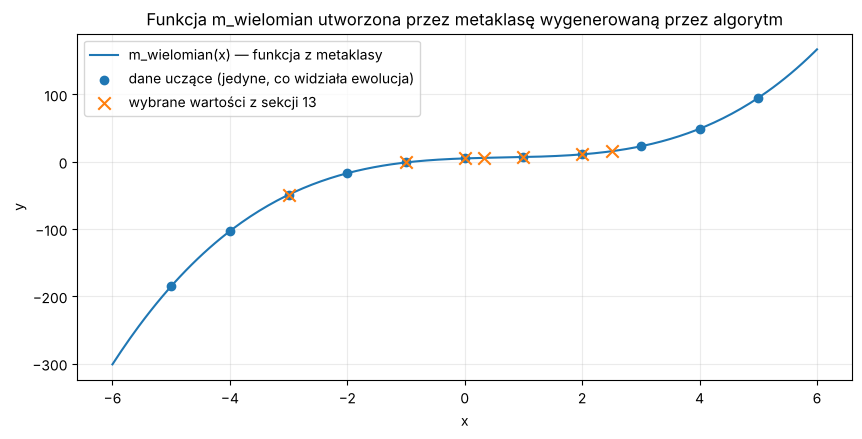

In [18]:
xs = [i / 20 for i in range(-120, 121)]

plt.figure(figsize=(10, 4.5))
plt.plot(xs, [m_wielomian(x) for x in xs], label="m_wielomian(x) — funkcja z metaklasy")
plt.scatter(X, Y, zorder=3, label="dane uczące (jedyne, co widziała ewolucja)")
punkty = [x for x in WYBRANE if -6 <= x <= 6]
plt.scatter(punkty, [m_wielomian(x) for x in punkty], marker="x", s=80, zorder=4,
            label="wybrane wartości z sekcji 13")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Funkcja m_wielomian utworzona przez metaklasę wygenerowaną przez algorytm")
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()

## Podsumowanie łańcucha autoprogramowania

1. **Ewolucja** wyhodowała drzewo programu wyłącznie z par wejście → wyjście.
2. **Redukcja symboliczna** zamieniła rozdęte drzewo na zwarty wielomian (bez zmiany wartości).
3. **Generator kodu** napisał tekst źródłowy metaklasy z wbudowaną wiedzą odkrytą przez ewolucję.
4. Tekst został sparsowany, skompilowany i wykonany — **metaklasa powstała w trakcie działania programu**.
5. Metaklasa zapytała użytkownika i po odpowiedzi **TAK!** zbudowała AST funkcji `m_wielomian`,
   skompilowała je i udostępniła jako zwykłą funkcję Pythona.
6. `m_wielomian` daje wyniki identyczne z drzewem GP i ukrytym wzorem — także daleko poza danymi uczącymi.